In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import fmatoolbox as fma
import isautilities as isau
import xarray as xr

import pathlib
froot = pathlib.Path().cwd().parent.parent.parent / 'Results' / 'Figures' / 'UnitEntrainment'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
do_save = False

In [2]:
def _ATM(session,regs=None,when='sleep.*#0',threshold=90,bin=0.05,diag=False):

    R = fma.regions.regions(session,epochs=when,states=['sws','rem'],events='InfraSlowRhythm/infraslowaval')
    regs = R.ids if regs is None else np.array(regs)[np.isin(regs,R.ids)]
    isa = R.eventIntervals('slownr')
    nrem = R.eventIntervals('sws')

    fr = R.firingRate(regs=regs, window=bin)
    time = fr[:,0]
    fr = fr[:,1:]

    ATM, intervals = fma.analysis.avalTransitionMatrix(fr, threshold=threshold, min_length=2, time_step=bin, t0=time[0])
    if not diag:
        idx = np.arange(ATM.shape[1])
        ATM[:,idx,idx] = np.nan
    is_isa = isau.isISA(intervals, isa, sleep=nrem)

    ATM = xr.DataArray(ATM,dims=('aval','reg0','reg1'),coords={'reg0': regs, 'reg1': regs, 'isa': ('aval',is_isa), 'rat': int(R.rat)})
    intervals = xr.DataArray(intervals,dims=('aval','val'),coords={'val': ['start','stop'], 'isa': ('aval',is_isa), 'rat': int(R.rat)})

    return ATM, intervals

In [21]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][8]
print(session)
ATM, intervals = _ATM(session)

/mnt/hubel-data-131/perceval/Rat003_20231223/Rat003_20231223.xml


(<matplotlib.image.AxesImage at 0x7ba4fcddfed0>,
 <matplotlib.colorbar.Colorbar at 0x7ba4fcdee900>)

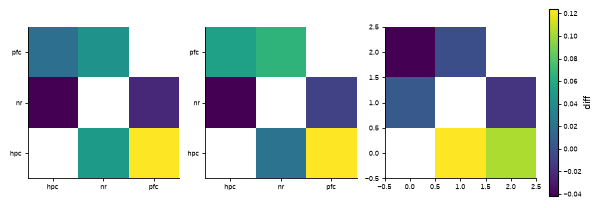

In [30]:
fig, ax = fma.plotting.figure(n=(1,3),size=(15,5))
for i in range(2):
    fma.plotting.plotColorMap(ATM.sel(isa=i).mean(dim='aval'), ax=ax[i])
    ax[i].set(xticks=range(3), xticklabels=ATM.reg0.values, yticks=range(3), yticklabels=ATM.reg1.values)
fma.plotting.plotColorMap(ATM.sel(isa=0).mean(dim='aval') - ATM.sel(isa=1).mean(dim='aval'), bar='diff', ax=ax[-1]);

batch

In [11]:
regs = ['hpc','nr','pfc']
ATM, intervals = fma.data.runBatch(batch_file, _ATM, kwargs={'regs':regs, 'threshold':95}, parallel=True)
ATM_cat = {}
for i, cond in enumerate(['ISA','nISA']):
    ATM_cat[cond] = []
    for d in ATM:
        if d is not None and i in d.isa:
            ATM_cat[cond].append(d.sel(isa=i).mean(dim='aval'))
    ATM_cat[cond] = xr.concat(ATM_cat[cond], dim='rat', coords='different', join='outer')


Starting Batch, 2026-10-19 14:33:59.186192 

Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.xml (41)
/mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.xml (42)
/mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.sws not found.
Traceback:
Batch completed with 5 errors, 2026-10-19 14:34:09

/tmp/ipykernel_2887084/3203554675.py:9: FutureWarning: In a future version of xarray the default value for compat will change from compat='equals' to compat='override'. This change will result in the following ValueError: Cannot specify both coords='different' and compat='override'. The recommendation is to set compat explicitly for this case.
  ATM_cat[cond] = xr.concat(ATM_cat[cond], dim='rat', coords='different', join='outer')
/tmp/ipykernel_2887084/3203554675.py:9: FutureWarning: In a future version of xarray the default value for compat will change from compat='equals' to compat='override'. This change will result in the following ValueError: Cannot specify both coords='different' and compat='override'. The recommendation is to set compat explicitly for this case.
  ATM_cat[cond] = xr.concat(ATM_cat[cond], dim='rat', coords='different', join='outer')


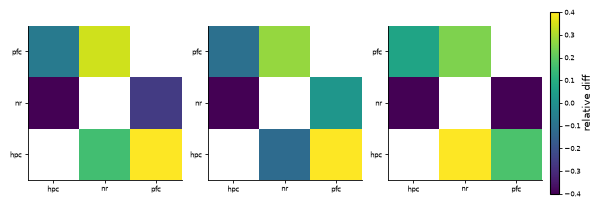

In [17]:
fig, ax = fma.plotting.figure(n=(1,3),size=(15,5))
for i, cond in enumerate(ATM_cat):
    fma.plotting.plotColorMap(ATM_cat[cond].mean(dim='rat'), ax=ax[i])
fma.plotting.plotColorMap((ATM_cat['ISA'].mean(dim='rat') - ATM_cat['nISA'].mean(dim='rat')) / ATM_cat['nISA'].mean(dim='rat'), vmin=-0.4, vmax=0.4, bar='relative diff', ax=ax[-1])
fma.plotting.setProp(ax, xticks=range(3), xticklabels=ATM_cat['ISA'].reg0.values, yticks=range(3), yticklabels=ATM_cat['ISA'].reg1.values)